# Your first trend

In this notebook, we create a **reproducible synthetic time series**, estimate a trend, and visualize the result. All calculations use the published finite-difference penalized least-squares smoother.

> **Scope:** Trend estimation is not a future-value forecast. This example is entirely simulated.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from trendestimation import TrendSmoother, plot_trend

rng = np.random.default_rng(42)
n = 100
t = np.linspace(0, 1, n)
true_trend = 2.0 * t + 0.45 * np.sin(2 * np.pi * t)
y = true_trend + rng.normal(0, 0.23, n)

## Fit the smoothed series

We use a **second-order difference penalty** and an illustrative fixed smoothing parameter, $\lambda=30$. A larger $\lambda$ generally produces a smoother fit.

Smoothness index: 0.853
Conditional effective degrees of freedom: 16.42


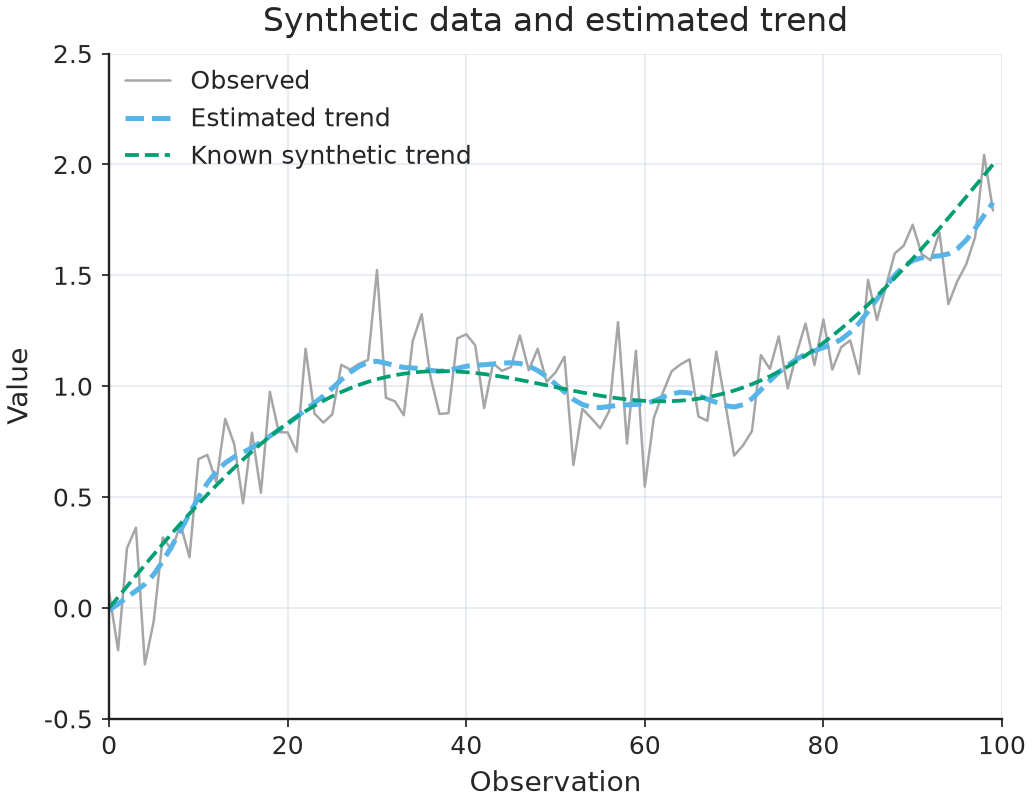

In [3]:
solver = TrendSmoother(n=n, order=2)
fit = solver.fit(y, lambda_=30.0, mu=0.0)
print(f"Smoothness index: {fit.smoothness:.3f}")
print(f"Conditional effective degrees of freedom: {fit.edf_conditional:.2f}")
ax = plot_trend(y, fit, title="Synthetic data and estimated trend")
ax.plot(true_trend, linestyle="--", linewidth=1.5, label="Known synthetic trend")
ax.legend()
plt.show()

## Interpret the result

- The observations contain a smooth signal and random noise.
- The fitted trend balances fidelity and smoothness.
- The known synthetic trend is available for illustration; real applications generally do not reveal the true trend.

Continue with [Choosing the smoothing parameter](02_select_smoothness.ipynb) or view the [API reference](../api.rst).

## Side-by-side penalty and normalized-smoothness coordinates

The following reproducible figures show the **same PLS estimator and fixed-mean CV/GCV/AICc/BIC scores** plotted against both the raw penalty $\lambda$ and normalized trace smoothness $S(\lambda)$. Both panels mark the same lowest-scoring **matched-grid** candidate. The final small timing chart runs the public GCV selector once in each coordinate. It is **illustrative only**, since the two default searches inspect different grids; controlled multi-seed timings belong to `benchmarks/criterion_coordinate_matrix.py` and `benchmarks/public_coordinate_optimizer_benchmark.py`.

Paired coordinates: last 60 observations of the notebook series; n=60, d=2, mu=0
Normalized S grid: [0.       0.1      0.2      0.3      0.4      0.5      0.6      0.7
 0.8      0.9      0.95     0.99     0.999    0.9999   0.999999 1.      ]
S=0 maps to lambda=0; S=1 maps to lambda=+infinity.
Near-1 targets: S=0.950000 -> lambda=886.169, S=0.990000 -> lambda=33003.8, S=0.999000 -> lambda=510198, S=0.999900 -> lambda=5.29957e+06, S=0.999999 -> lambda=5.32145e+08
Maximum inversion / round-trip error: 1.33e-15


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


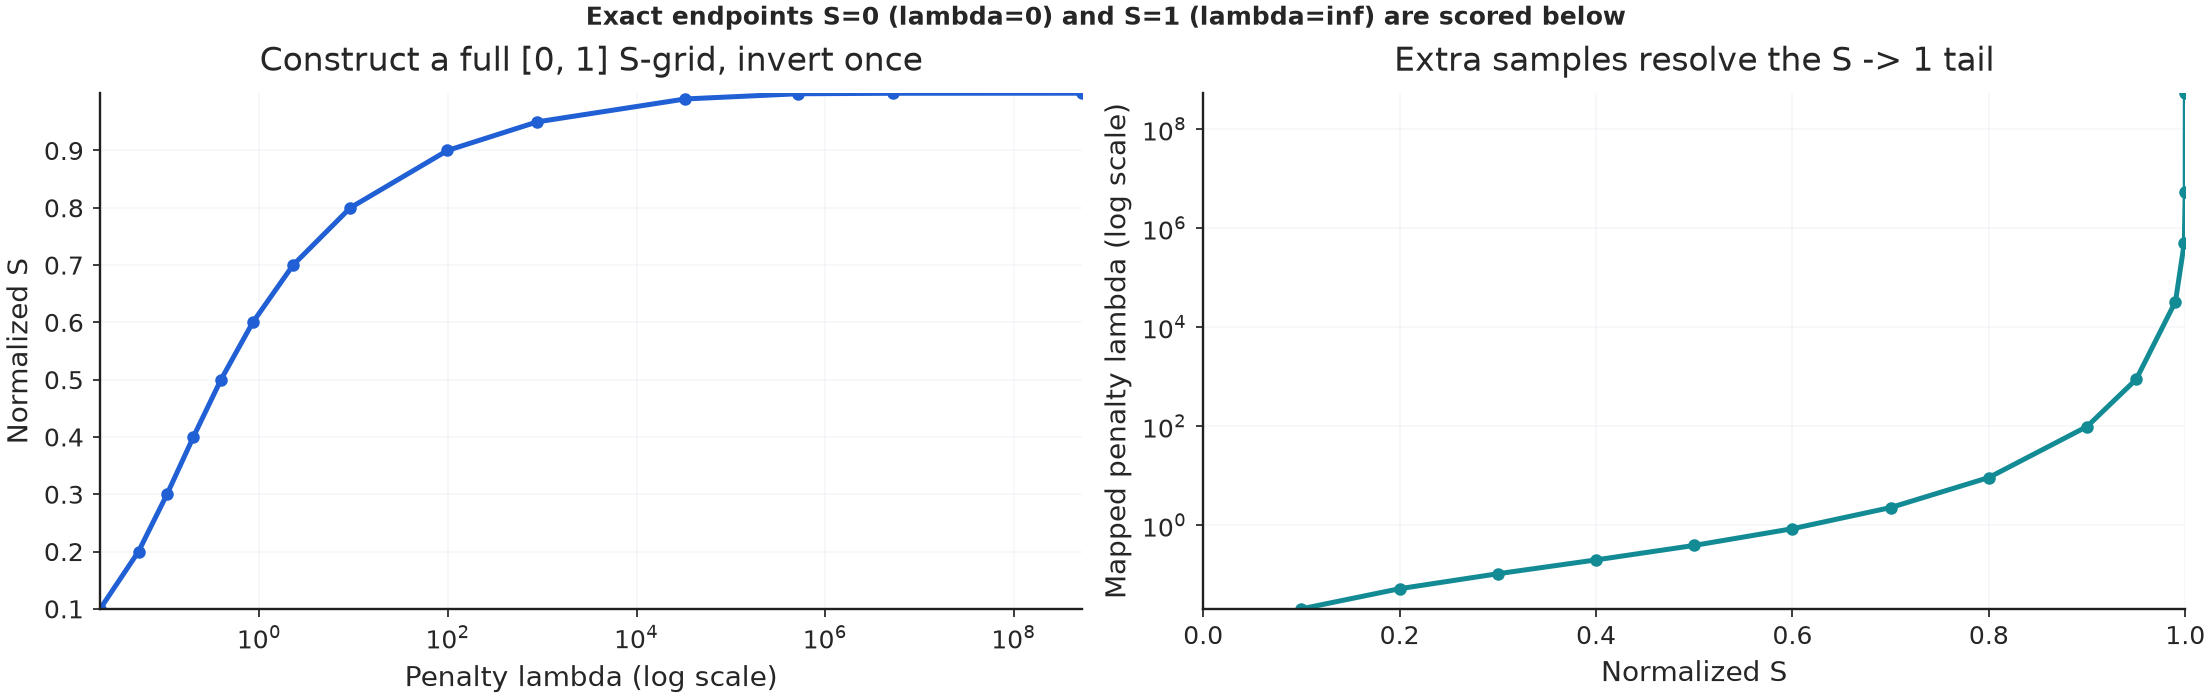

  CV: lambda=    9.21334, S=0.8, score=0.0292159
 GCV: lambda=    9.21334, S=0.8, score=0.0292107
AICC: lambda=    886.169, S=0.95, score=-3.48859
 BIC: lambda=  0.0205109, S=0.1, score=-3.93588


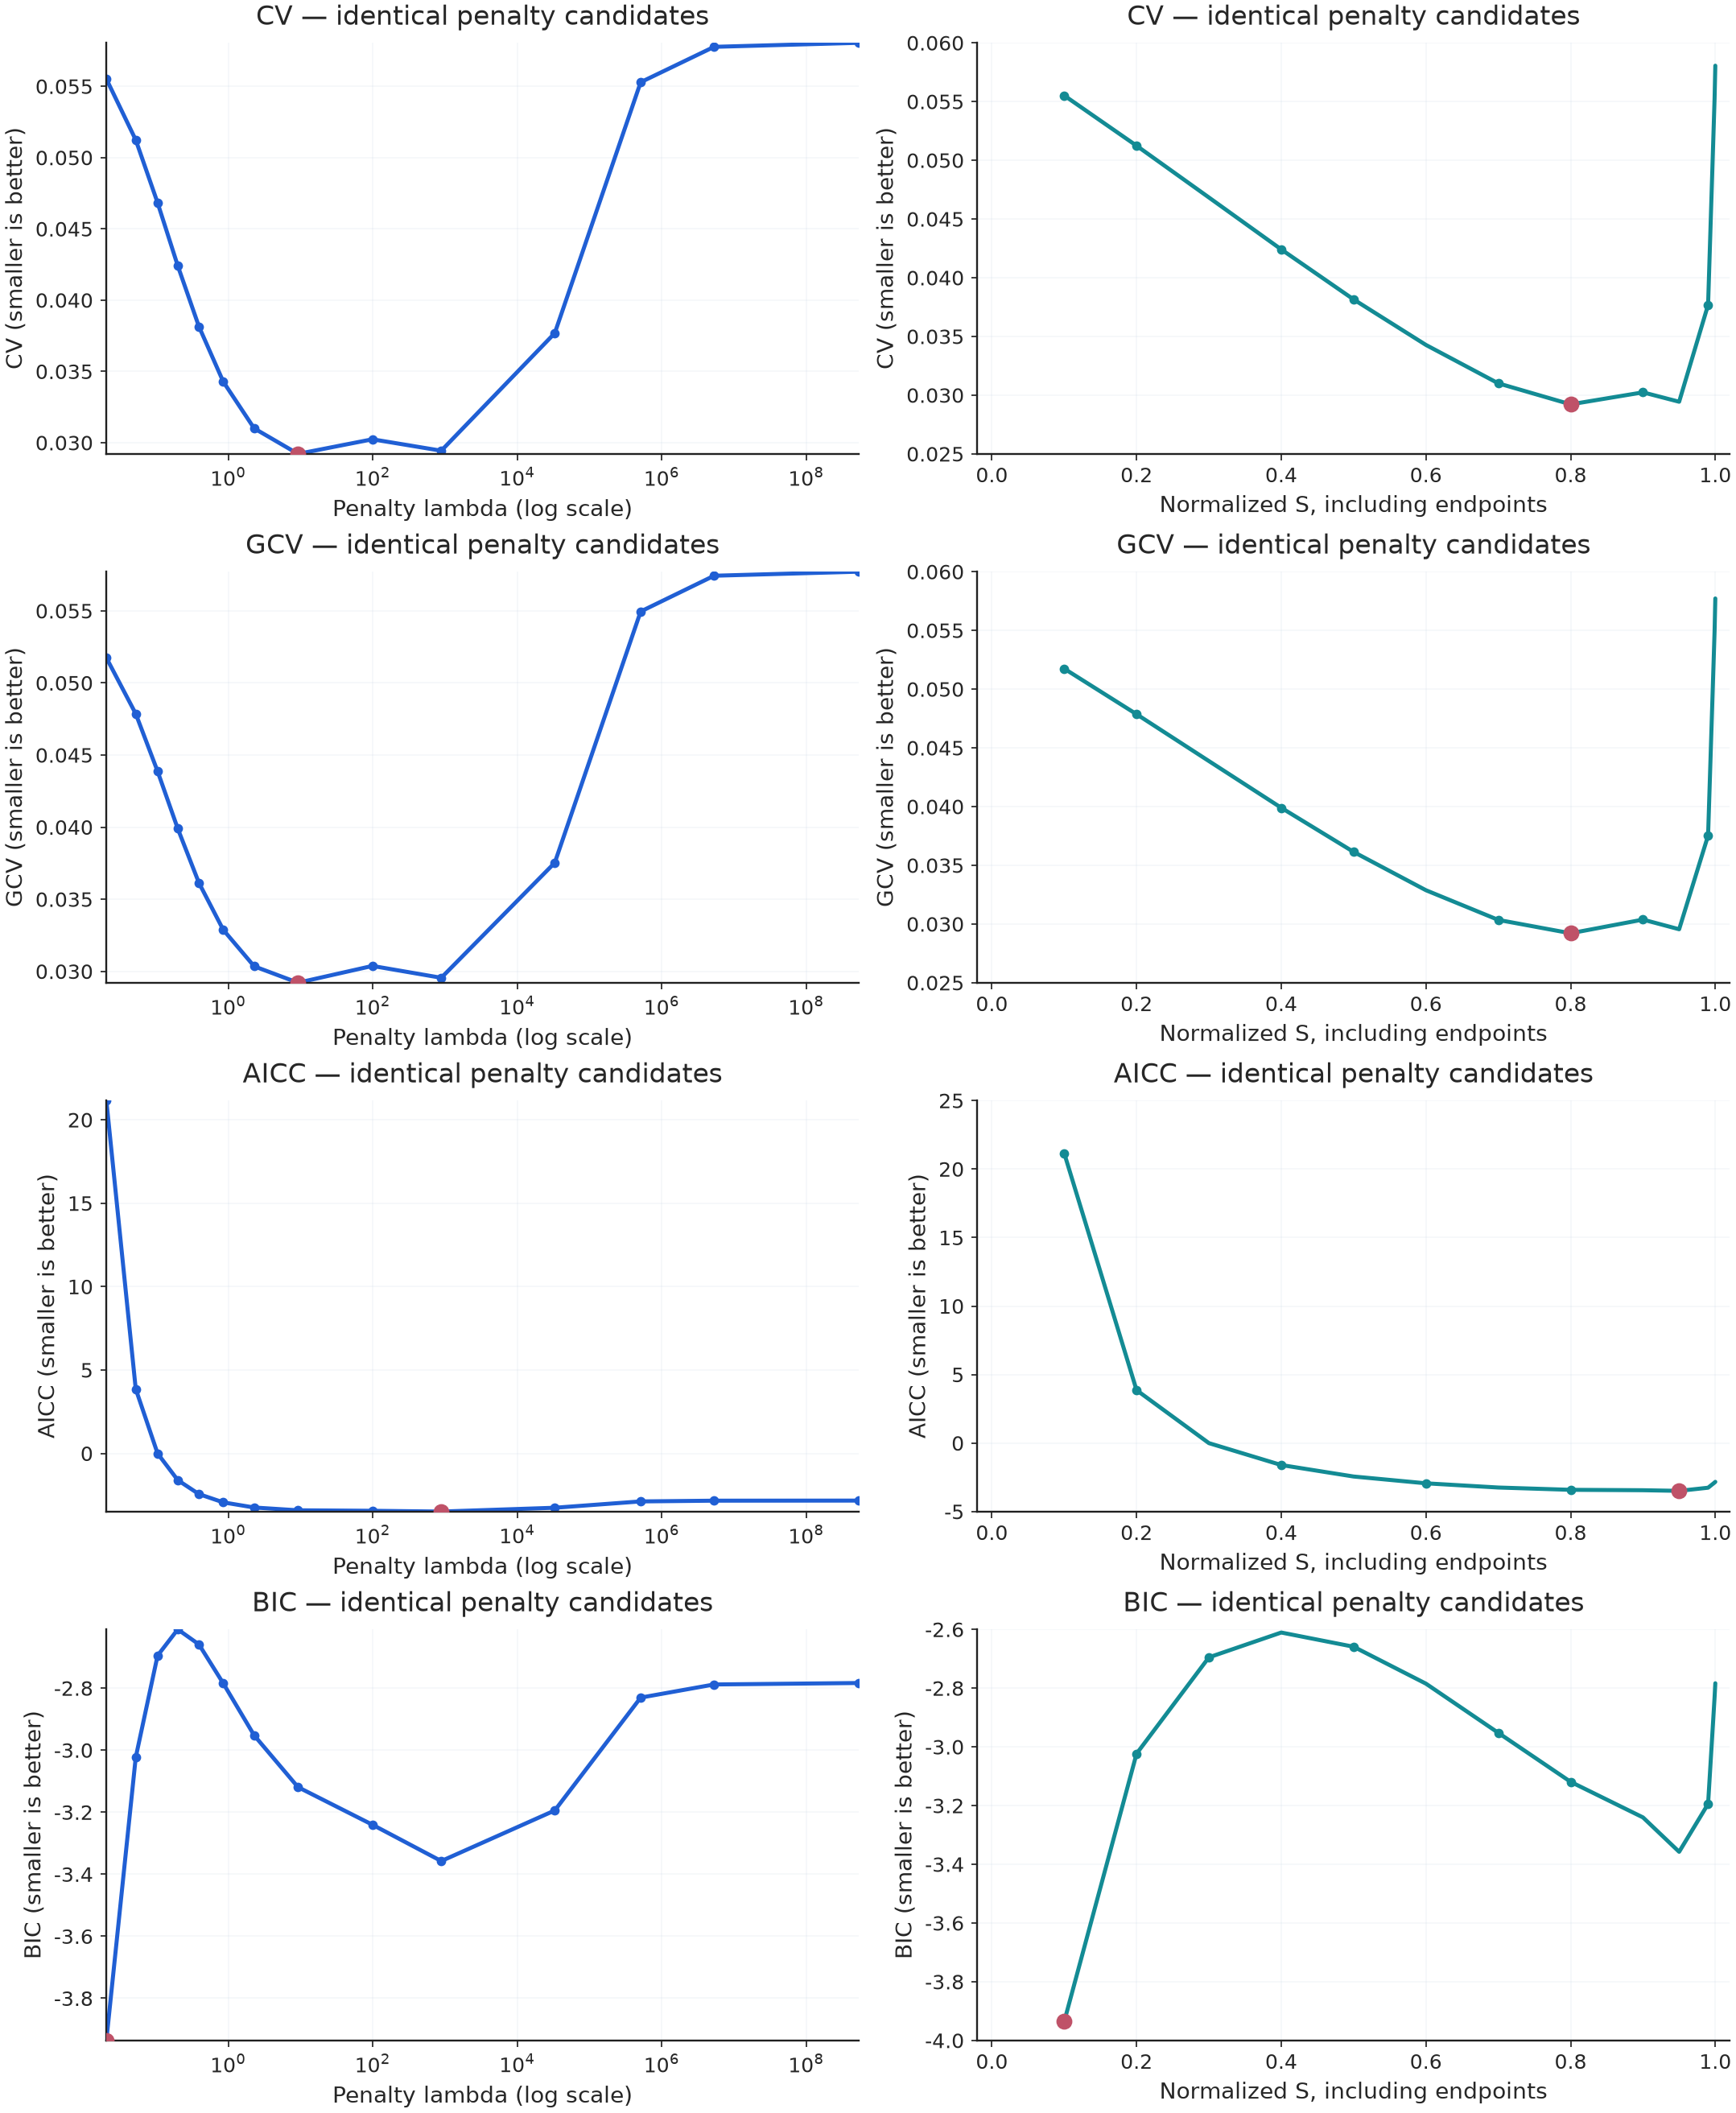

Left log-lambda plots omit 0 and infinity as coordinates, NOT as evaluated candidates. Right S plots include those endpoints. CV can be infinite at S=0 because unregularized LOOCV is undefined.


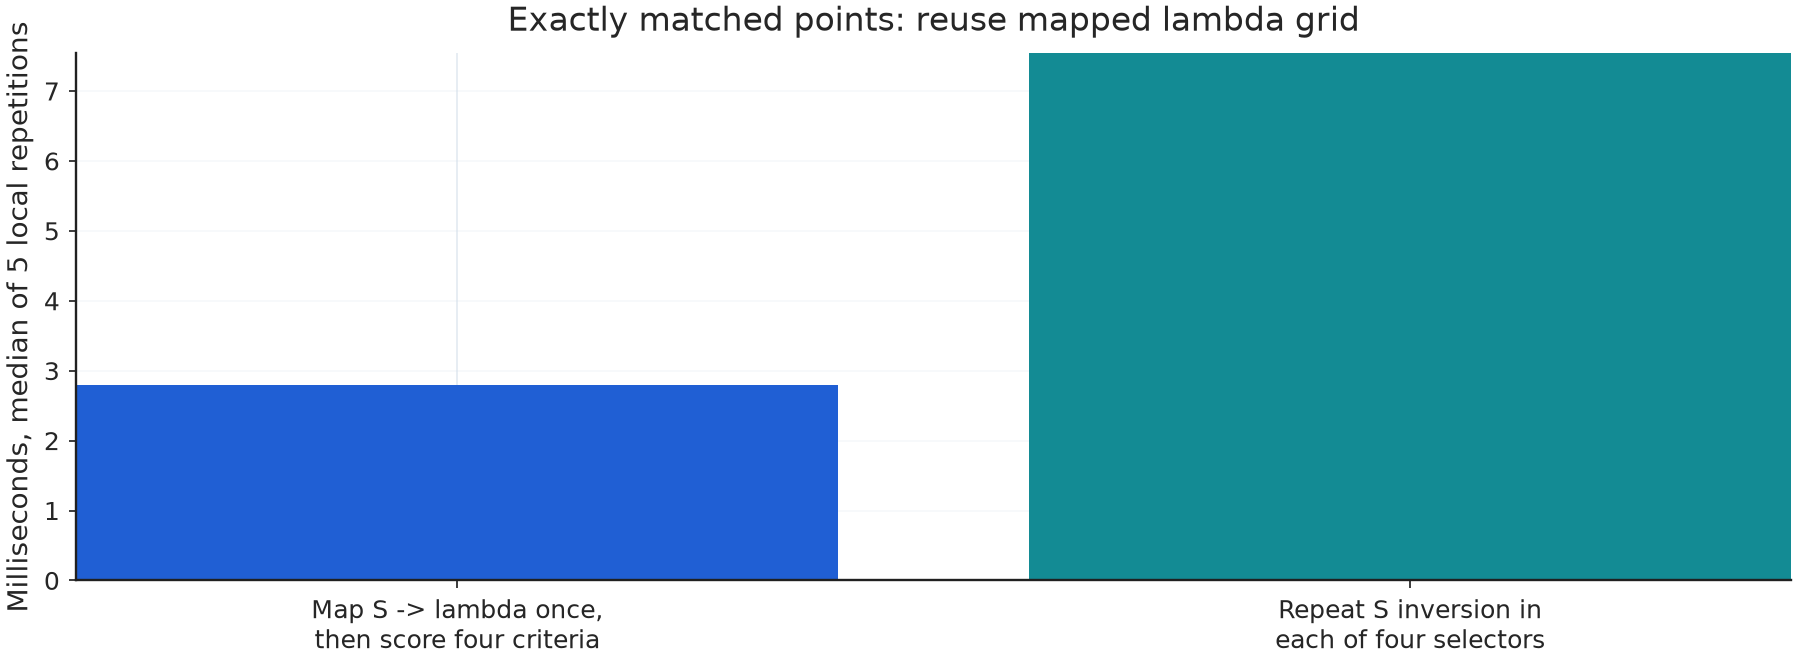

Four-criterion sweep, lambda-map-once: 2.794 ms; direct S selector (repeated mapping): 7.540 ms.
Both evaluate the same 16 penalties. This small, single-session measurement isolates a reusable-grid workflow, not the general speed of every optimization method or back end.


In [4]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

# Reuse notebook data when present; otherwise use a clearly labeled seeded example.
_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
